# 1. Why Subwords?

## The core problem

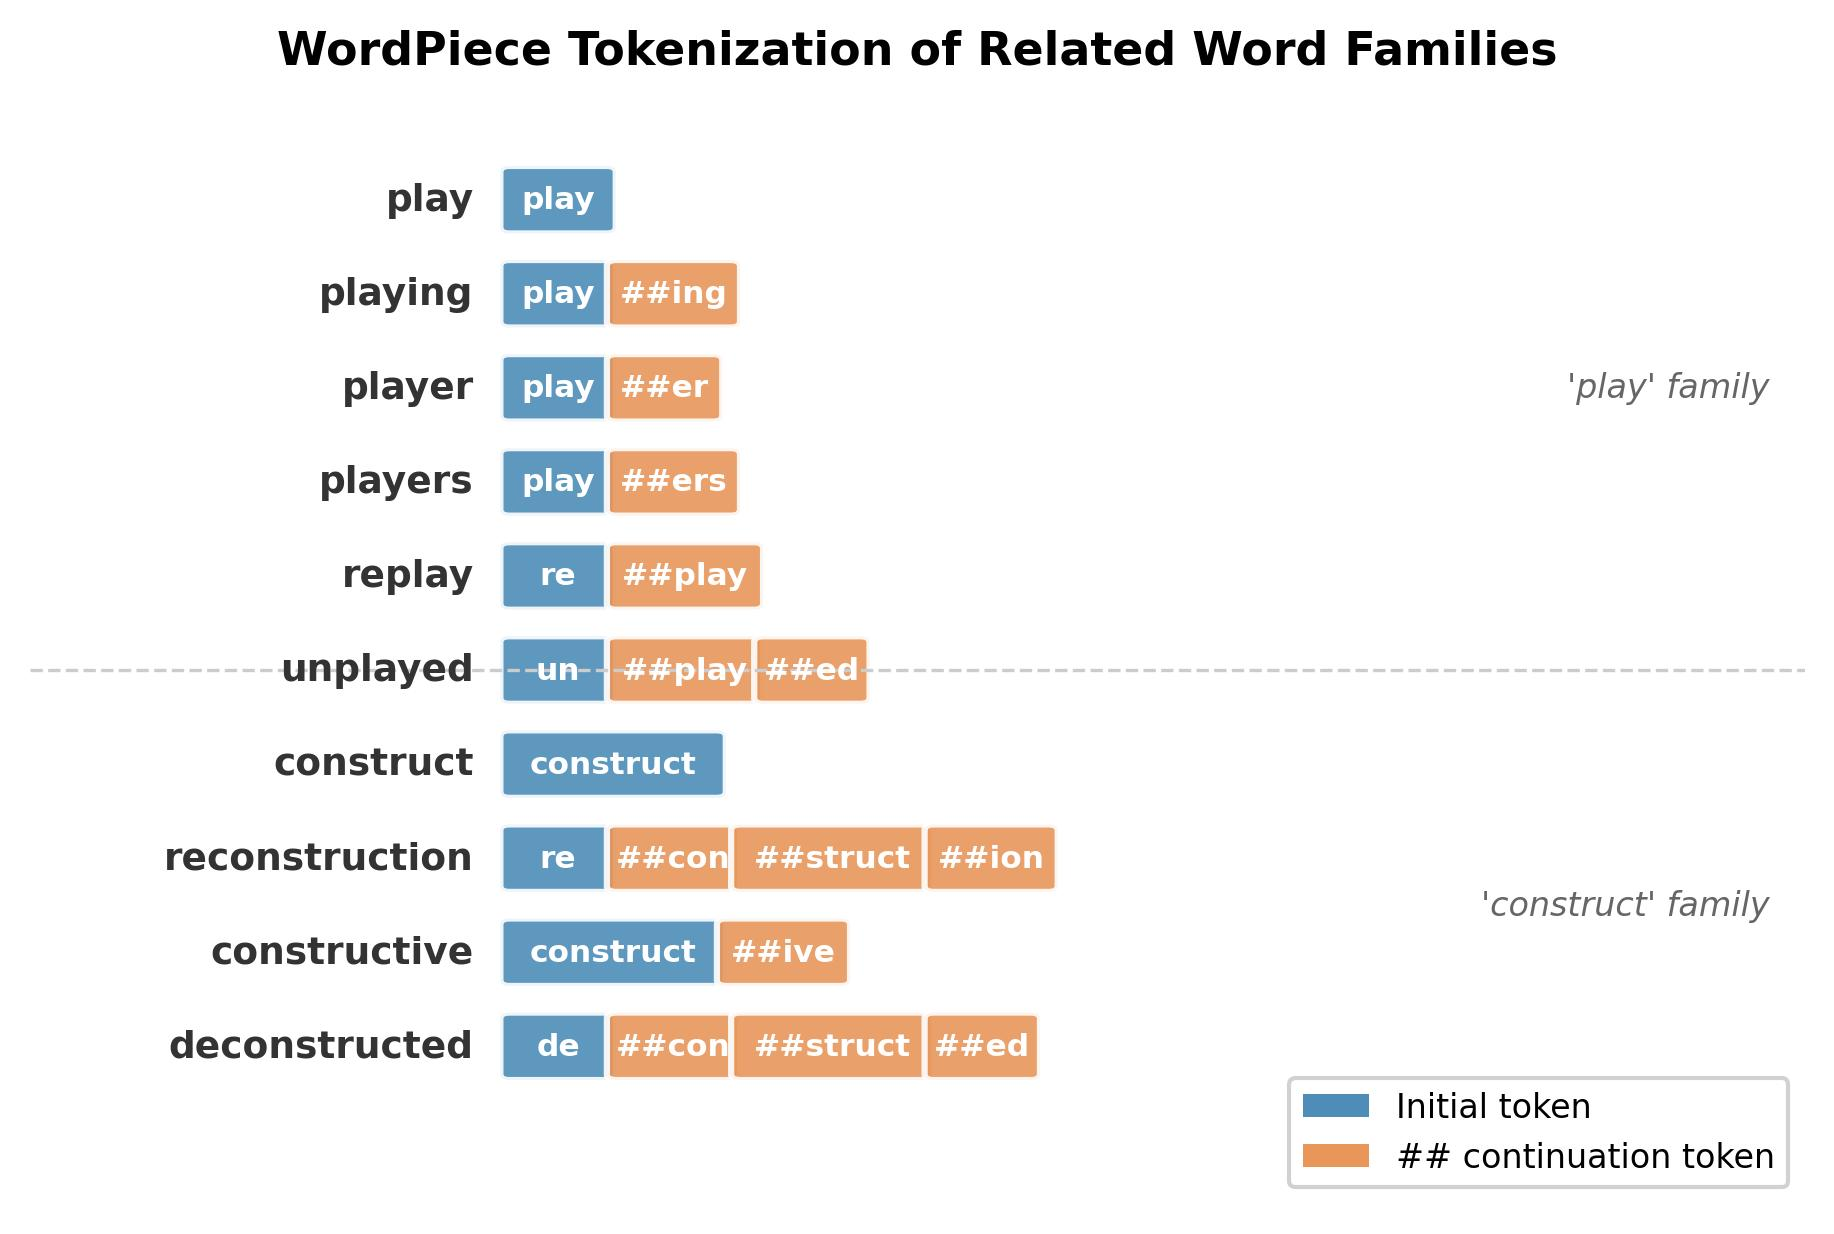

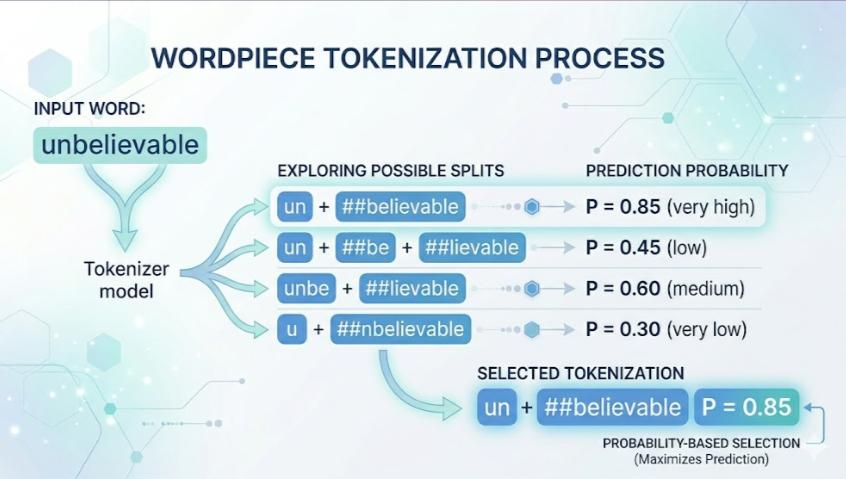

Suppose we use **word-level tokenization**:

```text
"I love machine learning"
        ↓
["I", "love", "machine", "learning"]
```

Each complete word becomes one token.

This seems natural, but it creates a major problem:

> **Language contains far more possible words than we can realistically keep in a vocabulary.**

For example:

```text
play
plays
played
playing
player
players
playful
playfulness
```

A word-level tokenizer may need to treat all of these as separate vocabulary entries.

Subword tokenization solves this by breaking words into **meaningful pieces**.

For example:

```text
playing → play + ing
players → player + s
unhappiness → un + happy + ness
```

The model can therefore reuse pieces across many words.

---

# 1.1 Unknown Words — OOV Problem

**OOV = Out Of Vocabulary**

Imagine our vocabulary contains:

```text
["I", "love", "machine", "learning", "NLP"]
```

Now we encounter:

```text
"I love transformers"
```

`transformers` isn't in the vocabulary.

A traditional word-level tokenizer might produce:

```text
["I", "love", "<UNK>"]
```

where `<UNK>` means **unknown token**.

The model loses the internal structure of the word.

### Subword approach

Instead, we might represent it as:

```text
transformers
     ↓
transform + ers
```

or, depending on the learned vocabulary:

```text
transformer + s
```

The exact segmentation depends on the tokenizer.

The important idea is:

> **We don't need the entire word in the vocabulary if we have reusable pieces.**

---

# 1.2 Rare Words

Consider:

```text
electroencephalographically
```

This word may occur extremely rarely in a training corpus.

With word-level tokenization:

```text
electroencephalographically
              ↓
        one vocabulary item
```

We would need a vocabulary entry specifically for this rare word.

With subwords:

```text
electro + encephalo + graph + ically
```

The tokenizer can potentially reuse these pieces in other words.

For example:

```text
graph
graphic
graphical
biography
photograph
```

The model doesn't have to learn every complete word independently.

### Key idea

**Word-level vocabulary**

```text
graph
graphic
graphical
photograph
biography
...
```

**Subword vocabulary**

```text
graph
photo
bio
graphic
ical
...
```

This allows **parameter sharing across related words**.

---

# 1.3 Misspellings

Real-world text is messy.

Users may write:

```text
"machineeeee learning"
"learnng"
"amazzzzing"
"transformerr"
```

A word-level tokenizer may encounter completely new words:

```text
learnng → <UNK>
amazzzzing → <UNK>
```

Subword tokenization provides a better chance of decomposing unfamiliar strings into known pieces.

For example, conceptually:

```text
learnng
 ↓
learn + ng
```

The exact result depends on the tokenizer vocabulary.

⚠️ **Important:** Subword tokenization does **not** magically understand spelling mistakes. It simply gives the tokenizer smaller reusable units, making unknown strings less likely to collapse entirely into `<UNK>`.

---

# 1.4 Morphology

This is one of the most important reasons to understand subwords.

**Morphology** studies how words are formed from smaller meaningful units.

Consider:

```text
unhappiness
```

It can be viewed as:

```text
un + happy + ness
```

Similarly:

```text
playing
   ↓
play + ing

played
   ↓
play + ed

players
   ↓
player + s
```

These words share components.

A word-level tokenizer treats them as completely independent:

```text
playing  → token A
played   → token B
players  → token C
```

Subword tokenization can expose some of the shared structure:

```text
play + ing
play + ed
player + s
```

This is particularly useful for languages with rich morphology.

---

# 1.5 Huge Vocabulary Problem

Suppose we try to include every word in our vocabulary.

We might need:

```text
10,000 words
100,000 words
1,000,000+ words
```

A larger vocabulary means:

- larger embedding matrix
- more memory
- more parameters
- more computation in vocabulary-related operations
- many rare entries

For a model with vocabulary size \(V\) and embedding dimension \(d\):

\[
\text{Embedding parameters} = V \times d
\]

For example:

\[
V=100,000,\qquad d=768
\]

gives:

\[
100,000 \times 768 = 76.8\text{ million}
\]

embedding parameters.

If we can represent many words using a smaller set of reusable subwords, we can keep vocabulary size more manageable.

---

# The Fundamental Trade-off

Subword tokenization is essentially trying to find a good middle ground:

```text
Character-level
      ↑
Very small vocabulary
Very long sequences
      │
      │
   SUBWORD
      │
      │
Word-level
      ↓
Large vocabulary
Shorter sequences
```

| Tokenization | Vocabulary | Sequence length | OOV handling |
|---|---:|---:|---|
| Character | Very small | Very long | Excellent |
| Word | Very large | Short | Poor |
| **Subword** | **Moderate** | **Moderate** | **Good** |

That's why modern NLP systems commonly use **subword-based tokenization**.

---

# A Simple Example

Consider:

```text
"unhappiness"
```

### Word-level

```text
["unhappiness"]
```

If `unhappiness` isn't in the vocabulary:

```text
["<UNK>"]
```

### Character-level

```text
["u","n","h","a","p","p","i","n","e","s","s"]
```

Very flexible, but that's **11 tokens**.

### Subword-level

Potentially:

```text
["un", "happi", "ness"]
```

Only **3 tokens**, while still preserving internal structure.

> **Subwords provide a practical compromise between words and characters.**

---

# Why This Matters for Transformers

Remember that a Transformer receives a sequence of tokens:

\[
x_1,x_2,\ldots,x_n
\]

and self-attention operates over those tokens.

Therefore, tokenization directly affects:

- **sequence length**
- **memory usage**
- **computational cost**
- **vocabulary size**
- **how rare/unseen words are represented**

This is especially important because self-attention has approximately:

\[
O(n^2)
\]

attention complexity with respect to sequence length \(n\).

So if poor tokenization turns:

```text
100 words → 180 tokens
```

into:

```text
100 words → 400 tokens
```

the attention computation can become substantially more expensive.

---

# 🧠 The Mental Model You Should Remember

Think of vocabulary as a **box of LEGO pieces**.

### Word-level

You store complete objects:

```text
🚗   🏠   🚲   ✈️
```

Every new object may require a new vocabulary item.

### Character-level

You store tiny pieces:

```text
🧱 🧱 🧱 🧱 🧱 ...
```

You can build almost anything, but it takes many pieces.

### Subword-level

You store reusable components:

```text
wheel
car
ing
ed
un
ness
...
```

Now you can construct many different words from a relatively compact vocabulary.

**That is the fundamental intuition behind subword tokenization.** 🔥

---

## What you should remember

1. **Word-level tokenization struggles with OOV and rare words.**
2. **Morphologically related words can share useful subword pieces.**
3. **Subwords reduce the need for enormous vocabularies.**
4. **Subwords handle previously unseen words better than pure word-level tokenization.**
5. **Subword tokenization is a compromise between word-level and character-level tokenization.**
6. **Tokenization affects Transformer sequence length and therefore computational cost.**

---